# 5-Class Random Forest Land Cover Classification

Uses optimal hyperparameters from GridSearchCV:
- n_estimators: 100
- min_samples_leaf: 3
- max_depth (maxNodes): 20

Classes: Forest (0), Water (1), Buildings (2), Soil (3), Agriculture (4)


In [24]:
import os
import ee
import geemap
from dotenv import load_dotenv
import seaborn as sns
import matplotlib.pyplot as plt

load_dotenv()
ee.Initialize(project=os.getenv('EE_PROJECT_ID'))



In [ ]:
# Define Jabalpur boundary using FAO GAUL (2025)
jabalpur = ee.FeatureCollection('FAO/GAUL/2025/level2').filter(
    ee.Filter.And(
        ee.Filter.eq('GAUL2_NAME', 'Jabalpur'),
        ee.Filter.eq('GAUL0_NAME', 'India')
    )
).geometry()

def mask_s2_clouds(image):
    qa = image.select('QA60')
    cloud  = 1 << 10
    cirrus = 1 << 11
    mask = qa.bitwiseAnd(cloud).eq(0).And(qa.bitwiseAnd(cirrus).eq(0))
    return image.updateMask(mask).divide(10000)

dataset = (
    ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
      .filterDate('2025-11-01', '2025-12-31')
      .filterBounds(jabalpur)
      .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 15))
      .map(mask_s2_clouds)
)
composite = dataset.median().clip(jabalpur)

ndvi = composite.normalizedDifference(['B8', 'B4']).rename('NDVI')
ndwi = composite.normalizedDifference(['B3', 'B8']).rename('NDWI')
ndbi = composite.normalizedDifference(['B11', 'B8']).rename('NDBI')
savi = composite.expression(
    '1.5 * (NIR - RED) / (NIR + RED + 0.5)',
    {'NIR': composite.select('B8'), 'RED': composite.select('B4')}
).rename('SAVI')

composite = composite.addBands([ndvi, ndwi, ndbi, savi])
bands = ['B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NDWI', 'NDBI', 'SAVI']


In [26]:
water       = ee.FeatureCollection('users/cosypix/jabalpur_water_points').map(lambda f: f.set('label', 1))
forest      = ee.FeatureCollection('users/cosypix/jabalpur_forest_points').map(lambda f: f.set('label', 0))
soil        = ee.FeatureCollection('users/cosypix/jabalpur_barren_points').map(lambda f: f.set('label', 3))
buildings   = ee.FeatureCollection('users/cosypix/jabalpur_urban_points').map(lambda f: f.set('label', 2))
agriculture = ee.FeatureCollection('users/cosypix/jabalpur_agriculture_points').map(lambda f: f.set('label', 4))

class_names = ['Forest', 'Water', 'Buildings', 'Soil', 'Agriculture']

all_points = water.merge(forest).merge(soil).merge(buildings).merge(agriculture)

training = (
    composite.select(bands)
             .sampleRegions(
                 collection=all_points,
                 properties=['label'],
                 scale=10
             )
             .filter(ee.Filter.notNull(bands + ['label']))
             .randomColumn('random', 42)
)

train_set = training.filter(ee.Filter.lt('random', 0.7))
test_set  = training.filter(ee.Filter.gte('random', 0.7))
print("Train Set Size:", train_set.size().getInfo())
print("Test Set Size:", test_set.size().getInfo())


Train Set Size: 3479
Test Set Size: 1521


Overall Accuracy: 0.8744247205785667
Kappa Coefficient: 0.8426448316878018

--- Class-wise Accuracy ---
Forest: 0.9311
Water: 0.9773
Buildings: 0.8480
Soil: 0.7441
Agriculture: 0.8900



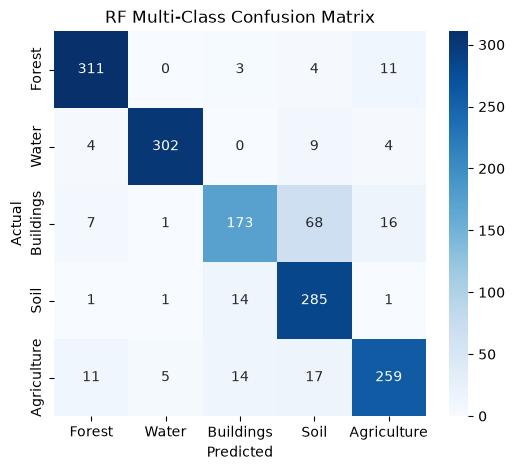

In [27]:
rf_classifier = ee.Classifier.smileRandomForest(
    numberOfTrees=100,
    minLeafPopulation=3,
    maxNodes=20
).train(
    features=train_set,
    classProperty='label',
    inputProperties=bands
)

test_classified = test_set.classify(rf_classifier)
confusion_matrix = test_classified.errorMatrix('label', 'classification')

print('Overall Accuracy:', confusion_matrix.accuracy().getInfo())
print('Kappa Coefficient:', confusion_matrix.kappa().getInfo())

print('\n--- Class-wise Accuracy ---')
consumers_acc = confusion_matrix.consumersAccuracy().getInfo()

for i, name in enumerate(class_names):
    # Safely access the 0th row, then the i-th column
    if i < len(consumers_acc[0]):
        acc = consumers_acc[0][i] if consumers_acc[0][i] is not None else 0.0
    else:
        acc = 0.0
        
    print(f'{name}: {acc:.4f}')

print()

cm_array = confusion_matrix.array().getInfo()

plt.figure(figsize=(6, 5))
sns.heatmap(cm_array, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('RF Multi-Class Confusion Matrix')
plt.show()

In [28]:
classified = composite.select(bands).classify(rf_classifier)
classified_smooth = classified.focalMode(radius=1, kernelType='square', units='pixels')

# Forest(0)=Green, Water(1)=Blue, Buildings(2)=Red, Soil(3)=Khaki, Agriculture(4)=Yellow/Orange
class_palette = ['1E8449', '2E86C1', 'C0392B', 'D4AC0D', 'F39C12']

Map = geemap.Map(center=[23.234, 79.976], zoom=10)
Map.addLayer(composite, {'bands': ['B4', 'B3', 'B2'], 'min': 0, 'max': 0.3}, 'RGB Composite')
Map.addLayer(classified_smooth, {'min': 0, 'max': 4, 'palette': class_palette}, 'RF Classification (5-Class)')

legend_dict = {
    'Forest (0)':      '1E8449',
    'Water (1)':       '2E86C1',
    'Buildings (2)':   'C0392B',
    'Soil (3)':        'D4AC0D',
    'Agriculture (4)': 'F39C12'
}
Map.add_legend(title='Land Cover', legend_dict=legend_dict)
Map.addLayer(jabalpur, {}, 'Jabalpur Boundary')
Map


Map(center=[23.234, 79.976], controls=(WidgetControl(options=['position', 'transparent_bg'], position='toprigh…

In [29]:
area_image = ee.Image.pixelArea().addBands(classified_smooth)
areas = area_image.reduceRegion(
    reducer=ee.Reducer.sum().group(groupField=1, groupName='class'),
    geometry=jabalpur,
    scale=30,
    maxPixels=1e10
)

area_data = areas.getInfo()['groups']
print("--- Class Areas for Jabalpur (Hectares) ---")
for entry in area_data:
    ha = entry['sum'] / 10000
    print(f"{class_names[entry['class']]}: {ha:.2f} ha")


--- Class Areas for Jabalpur (Hectares) ---
Forest: 81543.82 ha
Water: 14719.69 ha
Buildings: 31830.11 ha
Soil: 122353.03 ha
Agriculture: 258814.59 ha
